# Experiment A3 · Separate MAE encoder and decoder learning rates

**Complete** · 414/414 decisions · 2026-11-25T13:06:56+01:00

Reopen this notebook to see new measurements after the first decision, every six decisions and at completion.

## What A2 leaves open

Across all 414 A2 states, **8.2%** offered a shared-rate action that strictly improved both selector metrics at H=16/N=128. A separate count finds **0.0%** offered an action improving one with the other exactly flat. A2 tied the two LRs and its alternative rules were one-step comparisons on its Pareto policy’s trajectory. It could neither isolate a decoder update nor measure the frontier available to split rates at the same checkpoint. A3 addresses both questions. An independent trajectory for each competing policy and broader replication remain separate experiments.

## Paired test

The base LR is 0.003 for both components. All branches see the same single training frame and mask, with separate AdamW learning rates. A frozen component receives no gradient update, decay or moment-counter increment. Each frozen branch is checked against its parent for exact parameter, buffer and optimizer-state equality. Decoder-only RankMe is recomputed on both banks. Its probe scores reuse Skip’s scores after verifying encoder equality.

The A3 menu has 11 actions. The paired A2 control includes all six original shared rates (0, 0.1, 0.25, 0.5, 1 and 2×). Two extra tied-rate branches supply the controls missing from the proposed A3 menu. Only the 11 A3 actions may be committed. Both menus use the same parent, masks and label-free rules at every A3 state. At the initial state of each walk, shared-rate outcomes are also checked against archived A2 measurements.

The primary selector rejects historical RankMe decreases exceeding 0.1 of A2’s seed- and bank-specific calibration RMS. Among feasible actions it maximizes lookahead loss decrease and requires a gain greater than 0.1 of the horizon-specific loss RMS. Otherwise it skips. The reverse selector requires nondecreasing reconstruction performance and a RankMe gain greater than 0.1 of its RMS. Equal target scores prefer nondominated candidates, then the first listed action. Improvement categories use measured zero as their boundary, independently of the controller’s decision thresholds.

A3 reuses A2’s three checkpoints, six origin offsets, 23 clips, calibrated scales, four horizons, four historical bank sizes, within-clip frames and mask seeds. The primary selector at H=16/N=128 commits both model and optimizer state. All alternatives are locked before the x17–32 audit, separate audit bank and five external linear probes. Once commitments diverge the A3 trajectory can differ from the archived A2 trajectory.

## Does decoupling improve the attainable frontier?

Percentages below count states with at least one qualifying action. Strict-both requires positive gains on both objectives. One-only requires a positive gain on one and an exactly zero change on the other. A state can offer different actions in both categories. Zero-change Skip qualifies for neither. A frontier extension requires a point that the other menu cannot match or exceed on both axes.

| Menu at the same A3 states | Strict-both opportunity | One-only opportunity | Extends the other frontier |
|---|---:|---:|---:|
| A3 | 11.6% | 93.7% | 94.7% |
| A2 | 11.4% | 0.0% | 6.8% |

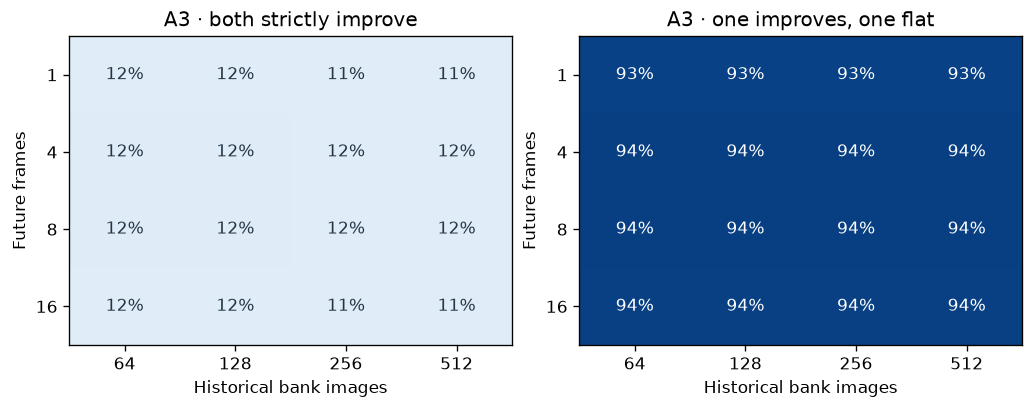

In [ ]:
# Embedded plot from the completed decision states.

## Selection and independent validation

All rows use H=16 and N=128. Audit loss gain uses the next disjoint 16 frames, and audit RankMe uses 128 separate historical captures. Probe gain and forgetting are in percentage points relative to Skip at the same state. Positive forgetting means the frozen probe heads lost accuracy. Each menu’s regret is relative to its own best held-out probe action.

| Menu / selector | Train | Both strictly improve¹ | One improves, one flat¹ | Audit loss gain | Audit rank gain | Δ probe Q | Forgetting | Regret |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| A3 · Minimize loss with rank guard | 88.9% | 2.4% | 78.3% | +0.027436 | +0.00192 | -0.003 | +0.219 | 0.252 |
| A3 · Maximize rank with loss guard | 4.6% | 4.6% | 0.0% | +0.002102 | +0.01115 | +0.004 | +0.122 | 0.244 |
| A2 · Minimize loss with rank guard | 47.3% | 6.3% | 0.0% | +0.007941 | -0.01205 | -0.024 | +0.592 | 0.273 |
| A2 · Maximize rank with loss guard | 4.8% | 4.8% | 0.0% | +0.001978 | +0.01137 | +0.003 | +0.124 | 0.246 |

¹ Measured on the lookahead and selection bank for the selected action.

## Decoder-only check

For 1242 independently measured decoder-only branches, maximum absolute RankMe change over all four bank sizes was **0** on selection and **0** on audit. At least one decoder-only LR improved local reconstruction in **93.7%** of states. The independent audit window showed a reconstruction improvement for at least one such LR in **94.0%**. Those two existence counts may refer to different rates.

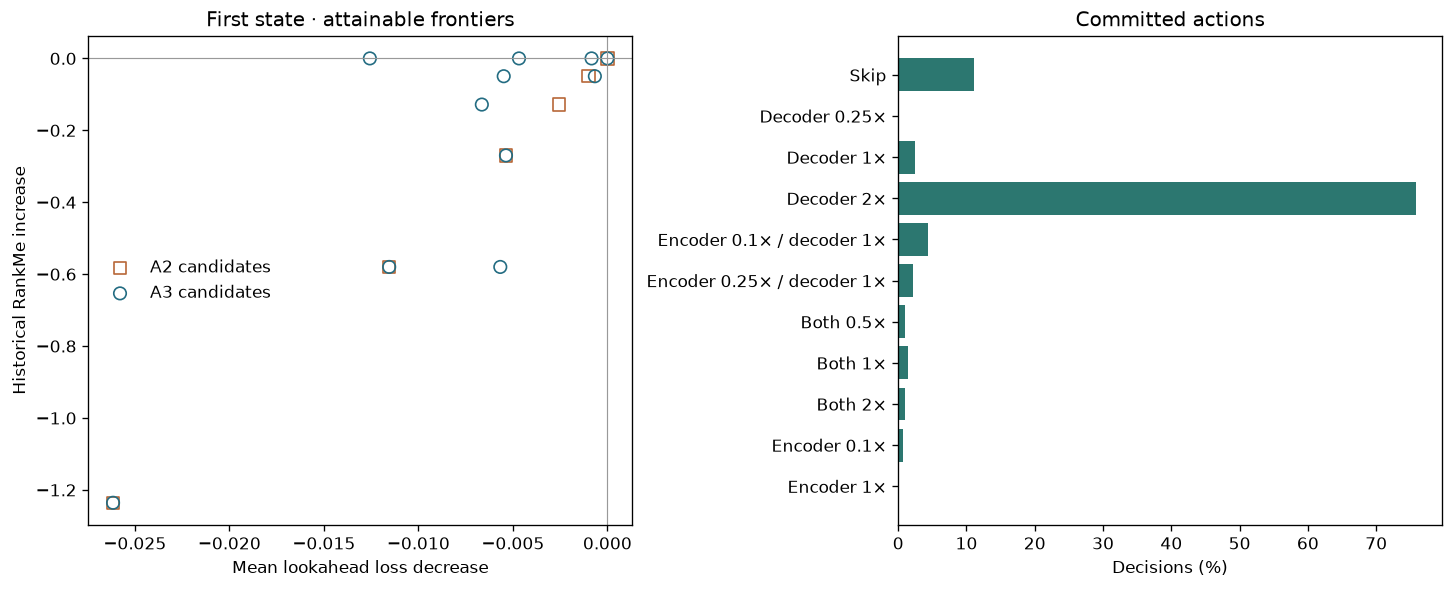

In [ ]:
# Embedded plot from the completed decision states.

## Inspect an origin

Edit the case index, horizon and bank size to inspect per-action losses, RankMe, probe Q and frontier membership.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

rel = Path("analysis/2026-11-09-one-step-mpc/mae-lookahead-a3/results")
out = next(p/rel for p in (Path.cwd(), *Path.cwd().parents) if (p/rel).is_dir())
files = sorted((out/"cases").glob("*.json"))
if files:
    case, h, n = 0, 16, 128
    spec = json.loads((out/"design.json").read_text())
    row = json.loads(files[case].read_text())
    hi, bi = [1,4,8,16].index(h), [64,128,256,512].index(n)
    loss = np.array(row["future"])[:,:h].mean(1)
    rank = np.array(row["rank"])[:,bi]
    table = pd.DataFrame(spec["actions"]).assign(loss_gain=loss[0]-loss, rank_gain=rank-rank[0],
        audit_loss=np.mean(row["audit_loss"],axis=1), audit_rank=np.array(row["audit_rank"])[:,bi],
        q=[b["q"] for b in row["quality"]])
    for menu, ix in spec["menus"].items():
        table.loc[ix, menu+" frontier"] = row["frontier"][menu][hi][bi]
        for k, policy in enumerate(spec["policies"]):
            table[menu+" "+policy] = table.index == row["choices"][menu][hi][bi][k]
    display(table)
else:
    print("Waiting for the first paired decision.")